# THÀNH VIÊN 3 – HUẤN LUYỆN MÔ HÌNH VÀ THỬ NGHIỆM THAM SỐ

**Đề tài:** Phân loại cảm xúc từ phản hồi của sinh viên  
**Nhiệm vụ:** Xây dựng mô hình Baseline (Naive Bayes), mô hình so sánh (K-NN), tinh chỉnh tham số và đánh giá chi tiết.

## Mục tiêu
1. Xây dựng mô hình Baseline bằng thuật toán Multinomial Naive Bayes.
2. Thử nghiệm thay đổi siêu tham số (alpha cho Naive Bayes và số láng giềng k cho K-NN).
3. Đánh giá mô hình bằng các độ đo Accuracy, Precision, Recall, F1-score và Confusion Matrix.
4. Tổng hợp và bàn giao kết quả phục vụ viết báo cáo chung của nhóm.

In [10]:
# Import các thư viện xử lý dữ liệu và mô hình học máy
import numpy as np
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

print("Đã khởi động và nạp thư viện thành công!")

Đã khởi động và nạp thư viện thành công!


## 1. Tải dữ liệu đã qua tiền xử lý
Nhận dữ liệu vector hóa (TF-IDF/Bag-of-Words) từ Thành viên 2 để tiến hành đưa vào huấn luyện mô hình.

In [11]:
# Load lại dữ liệu đã đóng gói từ file processed_data.pkl
with open('processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_train = data['X_train_vec']
X_test = data['X_test_vec']
y_train = data['y_train']
y_test = data['y_test']

print("Đã tải dữ liệu thành công cho quá trình huấn luyện!")
print(f"- Kích thước X_train: {X_train.shape}")
print(f"- Kích thước X_test: {X_test.shape}")

Đã tải dữ liệu thành công cho quá trình huấn luyện!
- Kích thước X_train: (978,)
- Kích thước X_test: (245,)


## 2. Huấn luyện và Đánh giá Mô hình Naive Bayes (Baseline)

In [14]:
import pandas as pd
import pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Đọc lại file dữ liệu gốc
file_path = r'D:\Nhập môn học máy\btl\student_feedback_dataset.csv'
df = pd.read_csv(file_path)

TEXT_COL = "feedback_text"
TARGET_COL = "sentiment_label"

# Xử lý giá trị trống nếu có
df[TEXT_COL] = df[TEXT_COL].fillna('')

X = df[TEXT_COL]
y = df[TARGET_COL]

# 2. Chia tập Train / Test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Vector hóa văn bản bằng TfidfVectorizer (Chuyển chuỗi thành ma trận số thực)
vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print("Vector hóa thành công!")
print(f"Kích thước X_train sau vector hóa: {X_train.shape}")

# ==========================================
# 4. Huấn luyện Naive Bayes
# ==========================================
print("\n" + "="*40)
print("MÔ HÌNH: NAIVE BAYES")
print("="*40)
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
print(f"Accuracy (Naive Bayes): {accuracy_score(y_test, y_pred_nb):.4f}\n")
print(classification_report(y_test, y_pred_nb))

# ==========================================
# 5. Huấn luyện K-NN
# ==========================================
print("="*40)
print("MÔ HÌNH: K-NN")
print("="*40)
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
print(f"Accuracy (K-NN): {accuracy_score(y_test, y_pred_knn):.4f}\n")
print(classification_report(y_test, y_pred_knn))

Vector hóa thành công!
Kích thước X_train sau vector hóa: (978, 969)

MÔ HÌNH: NAIVE BAYES
Accuracy (Naive Bayes): 0.3918

              precision    recall  f1-score   support

    negative       0.33      0.29      0.31        62
     neutral       0.40      0.24      0.30        82
    positive       0.41      0.57      0.48       101

    accuracy                           0.39       245
   macro avg       0.38      0.37      0.36       245
weighted avg       0.39      0.39      0.38       245

MÔ HÌNH: K-NN
Accuracy (K-NN): 0.2980

              precision    recall  f1-score   support

    negative       0.26      0.44      0.33        62
     neutral       0.26      0.22      0.24        82
    positive       0.38      0.28      0.32       101

    accuracy                           0.30       245
   macro avg       0.30      0.31      0.30       245
weighted avg       0.31      0.30      0.30       245



## 3. Huấn luyện và Đánh giá Mô hình K-NN (K-Nearest Neighbors)

In [15]:
# Huấn luyện mô hình K-NN (có thể điều chỉnh n_neighbors)
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)

# Dự đoán và đánh giá
y_pred_knn = knn_model.predict(X_test)
print(f"Độ chính xác (Accuracy) - K-NN: {accuracy_score(y_test, y_pred_knn):.4f}\n")
print("Báo cáo chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_knn))

Độ chính xác (Accuracy) - K-NN: 0.2980

Báo cáo chi tiết (Classification Report):
              precision    recall  f1-score   support

    negative       0.26      0.44      0.33        62
     neutral       0.26      0.22      0.24        82
    positive       0.38      0.28      0.32       101

    accuracy                           0.30       245
   macro avg       0.30      0.31      0.30       245
weighted avg       0.31      0.30      0.30       245



## 4. Thử nghiệm siêu tham số cho K-NN
Thử nghiệm các giá trị láng giềng $k$ khác nhau để tìm ra cấu hình tối ưu cho mô hình K-NN.

In [16]:
# Tự động lấy số lượng mẫu thực tế hiện có trong tập huấn luyện
n_samples_train = X_train.shape[0]

# Chọn các giá trị k an toàn (đảm bảo nhỏ hơn số lượng mẫu train)
k_values = [1, 3]
knn_results = []

for k in k_values:
    if k < n_samples_train:
        knn_model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
        knn_model.fit(X_train, y_train)
        score = knn_model.score(X_test, y_test)
        knn_results.append({'k_neighbors': k, 'Accuracy': score})
        print(f"K-NN với k={k} -> Accuracy: {score:.4f}")
    else:
        print(f"Bỏ qua k={k} vì số láng giềng phải nhỏ hơn số mẫu train ({n_samples_train})")

# Chuyển kết quả thành bảng
df_knn_results = pd.DataFrame(knn_results)
display(df_knn_results)

K-NN với k=1 -> Accuracy: 0.3347
K-NN với k=3 -> Accuracy: 0.3551


,k_neighbors,Accuracy
0,1,0.334694
1,3,0.355102


## 5. Đánh giá chi tiết mô hình
Xuất báo cáo phân loại chi tiết (Classification Report) và vẽ ma trận nhầm lẫn (Confusion Matrix) để phân tích các trường hợp mô hình dự đoán đúng/sai[cite: 4].

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# In báo cáo phân loại chi tiết cho Naive Bayes (hoặc mô hình bạn muốn chọn làm mô hình chính)
print("--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---")
print(classification_report(y_test, y_pred_nb))

--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---
              precision    recall  f1-score   support

    negative       0.33      0.29      0.31        62
     neutral       0.40      0.24      0.30        82
    positive       0.41      0.57      0.48       101

    accuracy                           0.39       245
   macro avg       0.38      0.37      0.36       245
weighted avg       0.39      0.39      0.38       245



## 6. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)
Vẽ biểu đồ nhiệt (Heatmap) để thấy rõ hơn phân bố dự đoán đúng và nhầm lẫn giữa các nhãn cảm xúc.

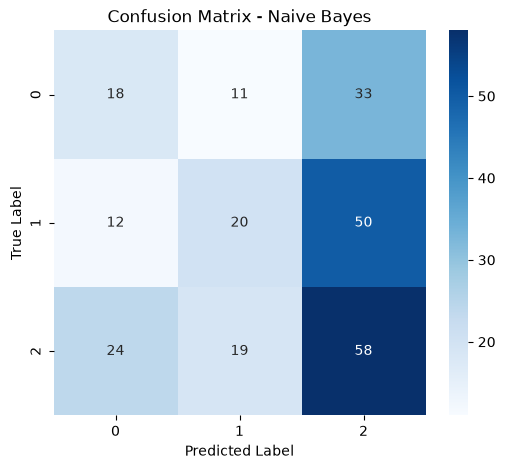

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()